In [1]:
print("hello")

hello


In [2]:

import numpy as np
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

import pickle
import numpy as np

ROOT = "."
SEED = 42

def load(filename):
    fh = open(ROOT + "/" + filename, "rb")
    d = pickle.load(fh, encoding="bytes")
    fh.close()

    x = d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b"labels"])

    return x, y


# Load all 5 training batches
parts = []

for i in range(1, 6):
    x, y = load("data_batch_" + str(i))
    parts.append((x, y))


# Combine all images and labels
xAll = np.concatenate([p[0] for p in parts])
yAll = np.concatenate([p[1] for p in parts])


# Select 50 images per class
rng = np.random.RandomState(SEED)

trainIdx = []
valdIdx = []

for c in range(10):
    idx = np.where(yAll == c)[0]
    idx = rng.permutation(idx)[:50]

    trainIdx.extend(idx[:40])
    valdIdx.extend(idx[40:50])


# Create training and validation datasets
x_train = xAll[trainIdx]
y_train = yAll[trainIdx]

x_val = xAll[valdIdx]
y_val = yAll[valdIdx]


# Save the datasets
np.savez_compressed("train_small_500.npz",x_train=x_train,y_train=y_train,x_val=x_val,y_val=y_val)

# Display dataset information
print("Train shape:", x_train.shape)
print("Val shape:", x_val.shape)
print("Train per class:", np.bincount(y_train))
print("Val per class:", np.bincount(y_val))


Train shape: (400, 32, 32, 3)
Val shape: (100, 32, 32, 3)
Train per class: [40 40 40 40 40 40 40 40 40 40]
Val per class: [10 10 10 10 10 10 10 10 10 10]


## Part A: Baseline

Epoch 1 | Train Acc: 10.0 | Val Acc: 10.0
Epoch 2 | Train Acc: 10.0 | Val Acc: 10.0
Epoch 3 | Train Acc: 17.0 | Val Acc: 16.0
Epoch 4 | Train Acc: 16.0 | Val Acc: 17.0
Epoch 5 | Train Acc: 17.5 | Val Acc: 17.0
Epoch 6 | Train Acc: 22.75 | Val Acc: 13.0
Epoch 7 | Train Acc: 23.25 | Val Acc: 21.0
Epoch 8 | Train Acc: 21.0 | Val Acc: 18.0
Epoch 9 | Train Acc: 25.0 | Val Acc: 16.0
Epoch 10 | Train Acc: 25.0 | Val Acc: 21.0
Epoch 11 | Train Acc: 26.0 | Val Acc: 21.0
Epoch 12 | Train Acc: 26.0 | Val Acc: 20.0
Epoch 13 | Train Acc: 28.25 | Val Acc: 25.0
Epoch 14 | Train Acc: 32.0 | Val Acc: 27.0
Epoch 15 | Train Acc: 28.0 | Val Acc: 20.0
Epoch 16 | Train Acc: 31.0 | Val Acc: 23.0
Epoch 17 | Train Acc: 30.0 | Val Acc: 10.0
Epoch 18 | Train Acc: 29.25 | Val Acc: 24.0
Epoch 19 | Train Acc: 31.0 | Val Acc: 27.0
Epoch 20 | Train Acc: 30.75 | Val Acc: 24.0
Epoch 21 | Train Acc: 33.25 | Val Acc: 26.0
Epoch 22 | Train Acc: 34.75 | Val Acc: 23.0
Epoch 23 | Train Acc: 33.25 | Val Acc: 26.0
Epoch 24 | T

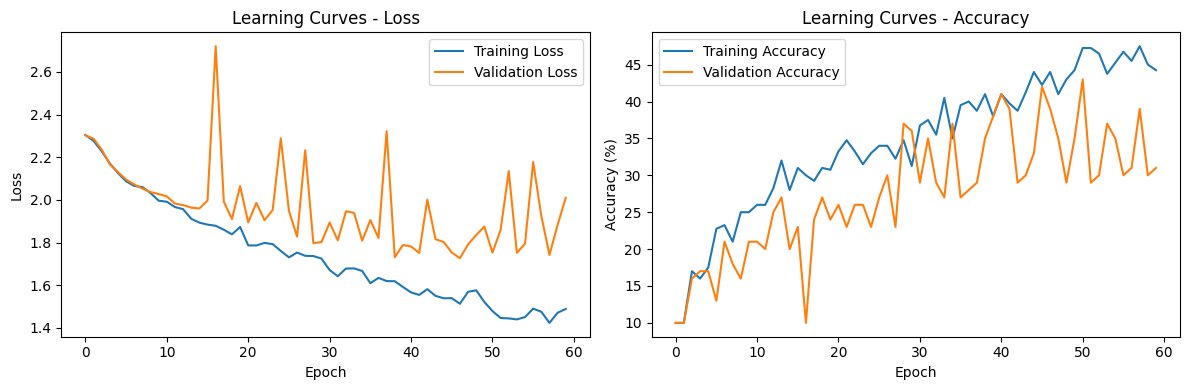

In [3]:

# Fixed seed
torch.manual_seed(42)
np.random.seed(42)

# Load training and validation data
data = np.load("train_small_500.npz")

x_train = torch.tensor(data["x_train"].transpose(0, 3, 1, 2), dtype=torch.float32) / 255.0
y_train = torch.tensor(data["y_train"], dtype=torch.long)

x_val = torch.tensor(data["x_val"].transpose(0, 3, 1, 2), dtype=torch.float32) / 255.0
y_val = torch.tensor(data["y_val"], dtype=torch.long)

trainLoader = DataLoader(TensorDataset(x_train, y_train), batch_size=32, shuffle=True)
valLoader = DataLoader(TensorDataset(x_val, y_val), batch_size=32, shuffle=False)

# Load clean test data
with open("test_batch", "rb") as f:
    testData = pickle.load(f, encoding="bytes")

x_clean = testData[b"data"].reshape(-1, 3, 32, 32)
x_clean = torch.tensor(x_clean, dtype=torch.float32) / 255.0
y_clean = torch.tensor(testData[b"labels"], dtype=torch.long)

cleanLoader = DataLoader(TensorDataset(x_clean, y_clean), batch_size=100, shuffle=False)

# Load shifted test data
shiftData = np.load("shifted_test.npz")

x_shift = shiftData["x_test"]
y_shift = shiftData["y_test"]

# Convert images from HWC to CHW if necessary
if x_shift.shape[1] == 32 and x_shift.shape[2] == 32:
    x_shift = x_shift.transpose(0, 3, 1, 2)

x_shift = torch.tensor(x_shift, dtype=torch.float32) / 255.0
y_shift = torch.tensor(y_shift, dtype=torch.long)

shiftLoader = DataLoader(TensorDataset(x_shift, y_shift), batch_size=100, shuffle=False)

# Inception-style block
class InceptionBlock(nn.Module):
    def __init__(self, inChannels, c1, c3, c5, cp):
        super().__init__()

        self.branch1 = nn.Conv2d(inChannels, c1, kernel_size=1)
        self.branch3 = nn.Sequential(nn.Conv2d(inChannels, 16, kernel_size=1),nn.ReLU(),nn.Conv2d(16, c3, kernel_size=3, padding=1))
        self.branch5 = nn.Sequential(nn.Conv2d(inChannels, 8, kernel_size=1),nn.ReLU(),nn.Conv2d(8, c5, kernel_size=5, padding=2))
        self.branchPool = nn.Sequential(nn.MaxPool2d(kernel_size=3, stride=1, padding=1),nn.Conv2d(inChannels, cp, kernel_size=1))

        self.relu = nn.ReLU()

    def forward(self, x):
        a = self.branch1(x)
        b = self.branch3(x)
        c = self.branch5(x)
        d = self.branchPool(x)

        x = torch.cat([a, b, c, d], dim=1)
        return self.relu(x)

# CNN model
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Sequential(nn.Conv2d(3, 32, kernel_size=3, padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2))

        self.inception1 = InceptionBlock(32, 16, 16, 8, 8)
        self.pool1 = nn.MaxPool2d(2)

        self.inception2 = InceptionBlock(48, 24, 16, 8, 8)

        self.avgPool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(56, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.inception1(x)
        x = self.pool1(x)
        x = self.inception2(x)
        x = self.avgPool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

model = BaselineCNN()

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Store results
trainLosses = []
valLosses = []
trainAccuracies = []
valAccuracies = []

bestValAcc = 0
bestModel = None

for epoch in range(60):

    model.train()
    totalLoss = 0
    correct = 0
    total = 0

    for images, labels in trainLoader:
        images = images
        labels = labels

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        totalLoss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    trainLosses.append(totalLoss / total)
    trainAccuracies.append(100 * correct / total)

    # Validation
    model.eval()
    totalLoss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valLoader:
            images = images
            labels = labels

            outputs = model(images)
            loss = criterion(outputs, labels)

            totalLoss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    valLosses.append(totalLoss / total)
    valAccuracies.append(100 * correct / total)

    if valAccuracies[-1] > bestValAcc:
        bestValAcc = valAccuracies[-1]
        bestModel = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    print("Epoch", epoch + 1,"| Train Acc:", round(trainAccuracies[-1], 2),"| Val Acc:", round(valAccuracies[-1], 2))

# Load the model with the best validation accuracy
model.load_state_dict(bestModel)
torch.save(model.state_dict(), "partA_best_model.pth")

# Function to calculate accuracy
def calculateAccuracy(loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images
            labels = labels

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

# Final accuracies
trainAcc = calculateAccuracy(trainLoader)
valAcc = calculateAccuracy(valLoader)
cleanAcc = calculateAccuracy(cleanLoader)
shiftAcc = calculateAccuracy(shiftLoader)

print("\nPART A RESULTS")
print("Training Accuracy:", round(trainAcc, 2), "%")
print("Validation Accuracy:", round(valAcc, 2), "%")
print("Clean Test Accuracy:", round(cleanAcc, 2), "%")
print("Shifted Test Accuracy:", round(shiftAcc, 2), "%")
print("Clean-Shifted Gap:", round(cleanAcc - shiftAcc, 2), "percentage points")

# Plot learning curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(trainLosses, label="Training Loss")
plt.plot(valLosses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning Curves - Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(trainAccuracies, label="Training Accuracy")
plt.plot(valAccuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Learning Curves - Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


## Part B: Design your augmentation strategy

Device: cpu
Seed 42 | Epoch 1 | Train Acc: 8.75 | Val Acc: 8.0
Seed 42 | Epoch 2 | Train Acc: 10.25 | Val Acc: 11.0
Seed 42 | Epoch 3 | Train Acc: 13.25 | Val Acc: 19.0
Seed 42 | Epoch 4 | Train Acc: 18.5 | Val Acc: 18.0
Seed 42 | Epoch 5 | Train Acc: 14.75 | Val Acc: 18.0
Seed 42 | Epoch 6 | Train Acc: 15.5 | Val Acc: 17.0
Seed 42 | Epoch 7 | Train Acc: 17.75 | Val Acc: 16.0
Seed 42 | Epoch 8 | Train Acc: 21.5 | Val Acc: 18.0
Seed 42 | Epoch 9 | Train Acc: 20.5 | Val Acc: 19.0
Seed 42 | Epoch 10 | Train Acc: 16.75 | Val Acc: 16.0
Seed 42 | Epoch 11 | Train Acc: 22.5 | Val Acc: 19.0
Seed 42 | Epoch 12 | Train Acc: 20.75 | Val Acc: 15.0
Seed 42 | Epoch 13 | Train Acc: 21.75 | Val Acc: 19.0
Seed 42 | Epoch 14 | Train Acc: 21.0 | Val Acc: 17.0
Seed 42 | Epoch 15 | Train Acc: 24.0 | Val Acc: 24.0
Seed 42 | Epoch 16 | Train Acc: 22.25 | Val Acc: 19.0
Seed 42 | Epoch 17 | Train Acc: 25.0 | Val Acc: 18.0
Seed 42 | Epoch 18 | Train Acc: 25.0 | Val Acc: 17.0
Seed 42 | Epoch 19 | Train Acc: 27.7

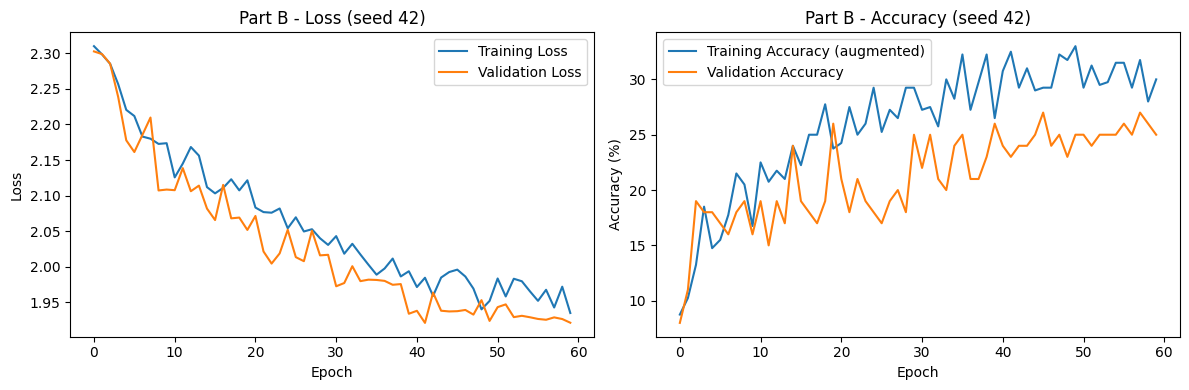

In [4]:

import numpy as np
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load data
data = np.load("train_small_500.npz")

x_train = data["x_train"]
y_train = data["y_train"]

x_val = torch.tensor(data["x_val"].transpose(0, 3, 1, 2), dtype=torch.float32) / 255.0
y_val = torch.tensor(data["y_val"], dtype=torch.long)

x_trainClean = torch.tensor(x_train.transpose(0, 3, 1, 2), dtype=torch.float32) / 255.0
y_trainClean = torch.tensor(y_train, dtype=torch.long)

valLoader = DataLoader(TensorDataset(x_val, y_val), batch_size=32, shuffle=False)
trainEvalLoader = DataLoader(TensorDataset(x_trainClean, y_trainClean), batch_size=100, shuffle=False)

with open("test_batch", "rb") as f:
    testData = pickle.load(f, encoding="bytes")

x_clean = torch.tensor(testData[b"data"].reshape(-1, 3, 32, 32), dtype=torch.float32) / 255.0
y_clean = torch.tensor(testData[b"labels"], dtype=torch.long)
cleanLoader = DataLoader(TensorDataset(x_clean, y_clean), batch_size=100, shuffle=False)

shiftData = np.load("shifted_test.npz")
x_shift = shiftData["x_test"]
y_shift = shiftData["y_test"]

if x_shift.shape[1] == 32 and x_shift.shape[2] == 32:
    x_shift = x_shift.transpose(0, 3, 1, 2)

x_shift = torch.tensor(x_shift, dtype=torch.float32) / 255.0
y_shift = torch.tensor(y_shift, dtype=torch.long)
shiftLoader = DataLoader(TensorDataset(x_shift, y_shift), batch_size=100, shuffle=False)


# Data augmentation
trainTransform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.4),
    transforms.ToTensor()
])


class AugmentData(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(self.images[index])
        if self.transform:
            image = self.transform(image)

        return image, int(self.labels[index])


# Model
class InceptionBlock(nn.Module):
    def __init__(self, inChannels, c1, c3, c5, cp):
        super().__init__()

        self.branch1 = nn.Conv2d(inChannels, c1, kernel_size=1)

        self.branch3 = nn.Sequential(nn.Conv2d(inChannels, 16, kernel_size=1),nn.ReLU(),nn.Conv2d(16, c3, kernel_size=3, padding=1))
        self.branch5 = nn.Sequential(nn.Conv2d(inChannels, 8, kernel_size=1),nn.ReLU(),nn.Conv2d(8, c5, kernel_size=5, padding=2))
        self.branchPool = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1),nn.Conv2d(inChannels, cp, kernel_size=1))
        self.relu = nn.ReLU()

    def forward(self, x):
        a = self.branch1(x)
        b = self.branch3(x)
        c = self.branch5(x)
        d = self.branchPool(x)

        return self.relu(torch.cat([a, b, c, d], dim=1))


class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Sequential(nn.Conv2d(3, 64, kernel_size=3, padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2))
        self.inception1 = InceptionBlock(64, 32, 32, 16, 16)
        self.pool1 = nn.MaxPool2d(2)
        self.inception2 = InceptionBlock(96, 48, 32, 16, 16)
        self.avgPool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(112, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.inception1(x)
        x = self.pool1(x)
        x = self.inception2(x)
        x = self.avgPool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)

        return self.fc(x)


def calculateAccuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


# Training
def trainOneSeed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    trainDataset = AugmentData(x_train, y_train, trainTransform)
    trainLoader = DataLoader(trainDataset, batch_size=32, shuffle=True)

    model = BaselineCNN().to(device)

    trainCriterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    valCriterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)

    trainLosses = []
    valLosses = []
    trainAccuracies = []
    valAccuracies = []

    bestValAcc = 0
    bestModel = None

    for epoch in range(60):
        model.train()
        totalLoss = 0
        correct = 0
        total = 0

        for images, labels in trainLoader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = trainCriterion(outputs, labels)
            loss.backward()
            optimizer.step()

            totalLoss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        scheduler.step()

        trainLosses.append(totalLoss / total)
        trainAccuracies.append(100 * correct / total)

        model.eval()
        totalLoss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in valLoader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = valCriterion(outputs, labels)

                totalLoss += loss.item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        valLosses.append(totalLoss / total)
        valAccuracies.append(100 * correct / total)

        if valAccuracies[-1] > bestValAcc:
            bestValAcc = valAccuracies[-1]
            bestModel = {}

            for name, value in model.state_dict().items():
                bestModel[name] = value.cpu().clone()

        print("Seed", seed,"| Epoch", epoch + 1,"| Train Acc:", round(trainAccuracies[-1], 2),"| Val Acc:", round(valAccuracies[-1], 2))

    model.load_state_dict(bestModel)
    results = {"train": calculateAccuracy(model, trainEvalLoader),"val": calculateAccuracy(model, valLoader),"clean": calculateAccuracy(model, cleanLoader),"shift": calculateAccuracy(model, shiftLoader)}
    curves = (trainLosses, valLosses, trainAccuracies, valAccuracies)
    return results, curves


# Run three seeds
seeds = [42, 43, 44]
allResults = []
firstCurves = None

for seed in seeds:
    results, curves = trainOneSeed(seed)
    allResults.append(results)

    if firstCurves is None:
        firstCurves = curves

    print("Seed", seed, "results:", {k: round(v, 2) for k, v in results.items()})

print("\nPART B RESULTS (mean +- std over 3 seeds)")

trainAcc = [r["train"] for r in allResults]
valAcc = [r["val"] for r in allResults]
cleanAcc = [r["clean"] for r in allResults]
shiftAcc = [r["shift"] for r in allResults]

print("Training Accuracy:", round(np.mean(trainAcc), 2), "+-", round(np.std(trainAcc), 2), "%")
print("Validation Accuracy:", round(np.mean(valAcc), 2), "+-", round(np.std(valAcc), 2), "%")
print("Clean Test Accuracy:", round(np.mean(cleanAcc), 2), "+-", round(np.std(cleanAcc), 2), "%")
print("Shifted Test Accuracy:", round(np.mean(shiftAcc), 2), "+-", round(np.std(shiftAcc), 2), "%")

gaps = [cleanAcc[i] - shiftAcc[i] for i in range(3)]
print("Clean-Shifted Gap:", round(np.mean(gaps), 2), "+-", round(np.std(gaps), 2), "percentage points")

# Learning curves for the first seed
trainLosses, valLosses, trainAccuracies, valAccuracies = firstCurves

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(trainLosses, label="Training Loss")
plt.plot(valLosses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Part B - Loss (seed 42)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(trainAccuracies, label="Training Accuracy (augmented)")
plt.plot(valAccuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Part B - Accuracy (seed 42)")
plt.legend()

plt.tight_layout()
plt.show()


## Part C: Regularization and training design

Trainable parameters: 47178
Seed 42 | Epoch 1 | Train Acc: 10.75 | Val Acc: 10.0 | Val Loss: 2.3113
Seed 42 | Epoch 2 | Train Acc: 18.25 | Val Acc: 12.0 | Val Loss: 2.2931
Seed 42 | Epoch 3 | Train Acc: 19.5 | Val Acc: 16.0 | Val Loss: 2.1767
Seed 42 | Epoch 4 | Train Acc: 21.25 | Val Acc: 17.0 | Val Loss: 2.1055
Seed 42 | Epoch 5 | Train Acc: 24.75 | Val Acc: 14.0 | Val Loss: 2.0842
Seed 42 | Epoch 6 | Train Acc: 23.5 | Val Acc: 26.0 | Val Loss: 1.9994
Seed 42 | Epoch 7 | Train Acc: 27.0 | Val Acc: 18.0 | Val Loss: 2.114
Seed 42 | Epoch 8 | Train Acc: 25.5 | Val Acc: 18.0 | Val Loss: 1.9423
Seed 42 | Epoch 9 | Train Acc: 22.25 | Val Acc: 17.0 | Val Loss: 2.0035
Seed 42 | Epoch 10 | Train Acc: 22.75 | Val Acc: 22.0 | Val Loss: 2.2592
Seed 42 | Epoch 11 | Train Acc: 26.25 | Val Acc: 28.0 | Val Loss: 1.98
Seed 42 | Epoch 12 | Train Acc: 26.75 | Val Acc: 25.0 | Val Loss: 1.9652
Seed 42 | Epoch 13 | Train Acc: 25.0 | Val Acc: 28.0 | Val Loss: 1.9237
Seed 42 | Epoch 14 | Train Acc: 27.75 | 

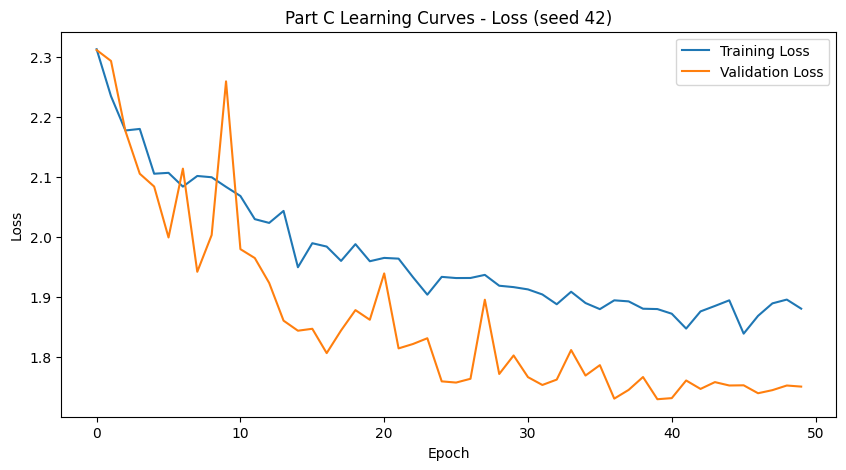

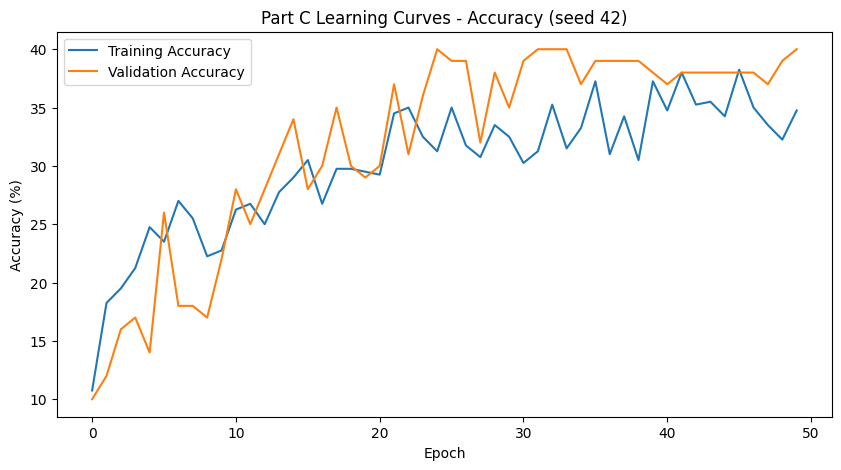

In [5]:
import copy
import random                                   
import pickle
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load training and validation data
data = np.load("train_small_500.npz")
x_train = data["x_train"]
y_train = data["y_train"]
x_val = data["x_val"]
y_val = data["y_val"]

# Load clean CIFAR-10 test data
with open("test_batch", "rb") as file:
    testData = pickle.load(file, encoding="bytes")

x_clean = testData[b"data"].reshape(-1, 3, 32, 32)
y_clean = np.array(testData[b"labels"])

# Load shifted test data
shiftData = np.load("shifted_test.npz")
x_shift = shiftData["x_test"]
y_shift = shiftData["y_test"]

if x_shift.ndim == 4 and x_shift.shape[-1] == 3:
    x_shift = x_shift.transpose(0, 3, 1, 2)
if x_train.ndim == 4 and x_train.shape[-1] == 3:
    x_train = x_train.transpose(0, 3, 1, 2)
if x_val.ndim == 4 and x_val.shape[-1] == 3:
    x_val = x_val.transpose(0, 3, 1, 2)

def prepareImages(images):
    images = torch.tensor(images, dtype=torch.float32)
    if images.max() > 1:
        images = images / 255.0
    return images

x_train_tensor = prepareImages(x_train)
x_val_tensor = prepareImages(x_val)
x_clean_tensor = prepareImages(x_clean)
x_shift_tensor = prepareImages(x_shift)

y_train_tensor = torch.tensor(y_train, dtype=torch.long).reshape(-1)
y_val_tensor = torch.tensor(y_val, dtype=torch.long).reshape(-1)
y_clean_tensor = torch.tensor(y_clean, dtype=torch.long).reshape(-1)
y_shift_tensor = torch.tensor(y_shift, dtype=torch.long).reshape(-1)

# Data augmentation (applied on the fly, training data only)
trainTransform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.4),
    transforms.RandomGrayscale(p=0.2),                                    # ADDED: hidden corruption
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.5, scale=(0.05, 0.25), value=0)          # ADDED: occlusion
])

class AugmentData(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index]
        if isinstance(image, torch.Tensor):
            image = image.cpu().numpy()
        if image.shape[0] == 3 and image.ndim == 3:
            image = image.transpose(1, 2, 0)
        if image.max() <= 1:
            image = (image * 255).astype(np.uint8)
        else:
            image = image.astype(np.uint8)
        image = Image.fromarray(image)
        image = self.transform(image)
        label = int(self.labels[index])
        return image, label

trainEvalLoader = DataLoader(TensorDataset(x_train_tensor, y_train_tensor), batch_size=32, shuffle=False)
valLoader = DataLoader(TensorDataset(x_val_tensor, y_val_tensor), batch_size=32, shuffle=False)
cleanLoader = DataLoader(TensorDataset(x_clean_tensor, y_clean_tensor), batch_size=32, shuffle=False)
shiftLoader = DataLoader(TensorDataset(x_shift_tensor, y_shift_tensor), batch_size=32, shuffle=False)

# Inception-style block
class InceptionBlock(nn.Module):
    def __init__(self, inChannels, out1, reduce3, out3, reduce5, out5):
        super().__init__()
        self.branch1 = nn.Sequential(
            nn.Conv2d(inChannels, out1, kernel_size=1), nn.BatchNorm2d(out1), nn.ReLU())
        self.branch3 = nn.Sequential(
            nn.Conv2d(inChannels, reduce3, kernel_size=1), nn.BatchNorm2d(reduce3), nn.ReLU(),
            nn.Conv2d(reduce3, out3, kernel_size=3, padding=1), nn.BatchNorm2d(out3), nn.ReLU())
        self.branch5 = nn.Sequential(
            nn.Conv2d(inChannels, reduce5, kernel_size=1), nn.BatchNorm2d(reduce5), nn.ReLU(),
            nn.Conv2d(reduce5, out5, kernel_size=5, padding=2), nn.BatchNorm2d(out5), nn.ReLU())
        self.branchPool = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(inChannels, out1, kernel_size=1), nn.BatchNorm2d(out1), nn.ReLU())
        self.relu = nn.ReLU()

    def forward(self, x):
        out = torch.cat([self.branch1(x), self.branch3(x), self.branch5(x), self.branchPool(x)], dim=1)
        return self.relu(out)

# CNN model for Part C
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))
        self.inception1 = InceptionBlock(64, 32, 32, 16, 16, 16)    # out = 32+16+16+32 = 96
        self.pool1 = nn.MaxPool2d(2)
        self.inception2 = InceptionBlock(96, 48, 32, 16, 16, 16)    # out = 48+16+16+48 = 128
        self.globalPool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.3)         
        self.fc = nn.Linear(128, 10)            #

    def forward(self, x):
        x = self.conv1(x)
        x = self.inception1(x)
        x = self.pool1(x)
        x = self.inception2(x)
        x = self.globalPool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)

def calculateAccuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images).argmax(1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

def trainOneSeed(seed):
    # CHANGED: full seeding for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    trainDataset = AugmentData(x_train, y_train, trainTransform)
    trainLoader = DataLoader(trainDataset, batch_size=32, shuffle=True)

    model = BaselineCNN().to(device)
    trainCriterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    valCriterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

    trainLosses, valLosses, trainAccuracies, valAccuracies = [], [], [], []
    bestValLoss = float("inf")
    bestModel = None
    patience = 10
    epochsWithoutImprovement = 0

    for epoch in range(60):
        model.train()
        totalLoss, correct, total = 0, 0, 0
        for images, labels in trainLoader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = trainCriterion(outputs, labels)
            loss.backward()
            optimizer.step()
            totalLoss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        trainLosses.append(totalLoss / total)
        trainAccuracies.append(100 * correct / total)

        model.eval()
        totalLoss, correct, total = 0, 0, 0
        with torch.no_grad():
            for images, labels in valLoader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = valCriterion(outputs, labels)
                totalLoss += loss.item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        valLoss = totalLoss / total
        valAccuracy = 100 * correct / total
        valLosses.append(valLoss)
        valAccuracies.append(valAccuracy)

        scheduler.step(valLoss)

        if valLoss < bestValLoss:
            bestValLoss = valLoss
            bestModel = copy.deepcopy(model.state_dict())
            epochsWithoutImprovement = 0
        else:
            epochsWithoutImprovement += 1

        print("Seed", seed, "| Epoch", epoch + 1,
              "| Train Acc:", round(trainAccuracies[-1], 2),
              "| Val Acc:", round(valAccuracy, 2),
              "| Val Loss:", round(valLoss, 4))

        if epochsWithoutImprovement >= patience:
            print("Early stopping at epoch", epoch + 1)
            break

    model.load_state_dict(bestModel)
    results = {
        "train": calculateAccuracy(model, trainEvalLoader),
        "val": calculateAccuracy(model, valLoader),
        "clean": calculateAccuracy(model, cleanLoader),
        "shift": calculateAccuracy(model, shiftLoader),
    }
    return results, (trainLosses, valLosses, trainAccuracies, valAccuracies)

# ADDED: verify the 1,000,000 parameter limit
print("Trainable parameters:",
      sum(p.numel() for p in BaselineCNN().parameters() if p.requires_grad))

# Run three seeds
seeds = [42, 43, 44]
allResults = []
firstSeedCurves = None
for seed in seeds:
    results, curves = trainOneSeed(seed)
    allResults.append(results)
    if seed == 42:
        firstSeedCurves = curves

print("\nPART C RESULTS (mean +/- std over 3 seeds)")
for metric in ["train", "val", "clean", "shift"]:
    values = [r[metric] for r in allResults]
    print(metric, ":", round(np.mean(values), 2), "+/-", round(np.std(values, ddof=1), 2))

gaps = [r["clean"] - r["shift"] for r in allResults]
print("Clean-Shifted Gap:", round(np.mean(gaps), 2), "+/-", round(np.std(gaps, ddof=1), 2))

# Learning curves (seed 42)
trainLosses, valLosses, trainAccuracies, valAccuracies = firstSeedCurves

plt.figure(figsize=(10, 5))
plt.plot(trainLosses, label="Training Loss")
plt.plot(valLosses, label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Part C Learning Curves - Loss (seed 42)")
plt.legend(); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(trainAccuracies, label="Training Accuracy")
plt.plot(valAccuracies, label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)")
plt.title("Part C Learning Curves - Accuracy (seed 42)")
plt.legend(); plt.show()

## Part D: Ablation study (mandatory)

Device: cpu
Trainable parameters: 32490

Configuration: No augmentation
Seed 42 | Epoch 1 | Train Acc: 15.0 | Val Acc: 10.0
Seed 42 | Epoch 2 | Train Acc: 26.0 | Val Acc: 11.0
Seed 42 | Epoch 3 | Train Acc: 31.25 | Val Acc: 19.0
Seed 42 | Epoch 4 | Train Acc: 34.0 | Val Acc: 22.0
Seed 42 | Epoch 5 | Train Acc: 36.25 | Val Acc: 27.0
Seed 42 | Epoch 6 | Train Acc: 38.25 | Val Acc: 34.0
Seed 42 | Epoch 7 | Train Acc: 41.25 | Val Acc: 31.0
Seed 42 | Epoch 8 | Train Acc: 42.75 | Val Acc: 37.0
Seed 42 | Epoch 9 | Train Acc: 46.0 | Val Acc: 32.0
Seed 42 | Epoch 10 | Train Acc: 47.25 | Val Acc: 38.0
Seed 42 | Epoch 11 | Train Acc: 50.75 | Val Acc: 33.0
Seed 42 | Epoch 12 | Train Acc: 55.25 | Val Acc: 34.0
Seed 42 | Epoch 13 | Train Acc: 51.5 | Val Acc: 33.0
Seed 42 | Epoch 14 | Train Acc: 55.0 | Val Acc: 41.0
Seed 42 | Epoch 15 | Train Acc: 54.0 | Val Acc: 36.0
Seed 42 | Epoch 16 | Train Acc: 56.25 | Val Acc: 36.0
Seed 42 | Epoch 17 | Train Acc: 55.75 | Val Acc: 44.0
Seed 42 | Epoch 18 | Train

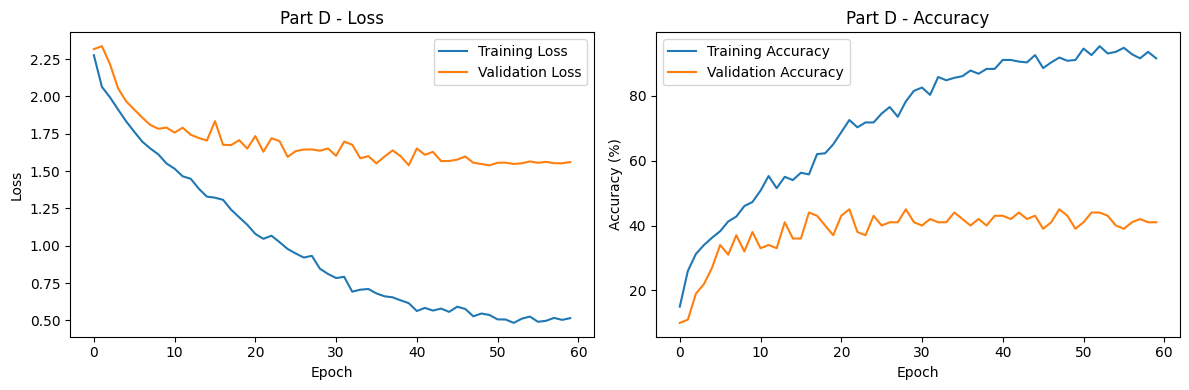

In [6]:

import random
import pickle
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms


# Fixed settings
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seeds = [42, 43, 44]
MAX_EPOCHS = 60
PATIENCE = 12

print("Device:", device)


# Load training and validation data
data = np.load("train_small_500.npz")

x_train = data["x_train"]
y_train = np.asarray(data["y_train"]).reshape(-1)

x_val = data["x_val"]
y_val = np.asarray(data["y_val"]).reshape(-1)


# Convert images to HWC format for PIL
def to_hwc(images):
    if images.ndim == 4 and images.shape[1] == 3:
        images = images.transpose(0, 2, 3, 1)
    return images


x_train = to_hwc(x_train)
x_val = to_hwc(x_val)


# Convert images to CHW tensors for evaluation
def to_tensor(images):
    if images.ndim == 4 and images.shape[-1] == 3:
        images = images.transpose(0, 3, 1, 2)

    images = torch.tensor(images.copy(), dtype=torch.float32)

    if images.max() > 1:
        images = images / 255.0

    return images


x_train_eval = to_tensor(x_train)
x_val_tensor = to_tensor(x_val)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

trainEvalLoader = DataLoader(TensorDataset(x_train_eval, y_train_tensor),batch_size=100,shuffle=False)

valLoader = DataLoader(TensorDataset(x_val_tensor, y_val_tensor),batch_size=100,shuffle=False)

# Load clean test data
with open("test_batch", "rb") as f:
    testData = pickle.load(f, encoding="bytes")

x_clean = testData[b"data"].reshape(-1, 3, 32, 32)
y_clean = np.asarray(testData[b"labels"]).reshape(-1)

x_clean = to_tensor(x_clean)
y_clean = torch.tensor(y_clean, dtype=torch.long)

cleanLoader = DataLoader(TensorDataset(x_clean, y_clean),batch_size=100,shuffle=False)

# Load shifted test data
shiftData = np.load("shifted_test.npz")

x_shift = shiftData["x_test"]
y_shift = np.asarray(shiftData["y_test"]).reshape(-1)

x_shift = to_tensor(x_shift)
y_shift = torch.tensor(y_shift, dtype=torch.long)

shiftLoader = DataLoader(TensorDataset(x_shift, y_shift),batch_size=100,shuffle=False)

# Add noise to tensor images
class AddGaussianNoise:
    def __init__(self, std=0.05):
        self.std = std

    def __call__(self, image):
        noise = torch.randn_like(image) * self.std
        return torch.clamp(image + noise, 0, 1)


# Augmentation components
geometric = [transforms.RandomCrop(32, padding=4),transforms.RandomHorizontalFlip(p=0.5),transforms.RandomRotation(25)]

photometric = [transforms.ColorJitter(brightness=0.5,contrast=0.5,saturation=0.4),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0))],p=0.3)]

# Configuration 1: No augmentation
noAugmentation = transforms.Compose([transforms.ToTensor()])

# Configuration 2: Geometric only
geometricOnly = transforms.Compose(geometric + [transforms.ToTensor()])

# Configuration 3: Photometric only
photometricOnly = transforms.Compose(photometric + [transforms.ToTensor(),AddGaussianNoise(0.05)])

# Configuration 4: Geometric + photometric
geometricPhotometric = transforms.Compose(geometric + photometric + [transforms.ToTensor(),AddGaussianNoise(0.05)])

# Configuration 5: Add Random Erasing
withErasing = transforms.Compose(geometric + photometric + [transforms.ToTensor(),AddGaussianNoise(0.05),transforms.RandomErasing(p=0.5,scale=(0.05, 0.25),value=0)])

# Dataset applies augmentation on the fly
class AugmentData(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(
            self.images[index].astype(np.uint8)
        )

        image = self.transform(image)
        label = int(self.labels[index])

        return image, label


# Inception-style block
class InceptionBlock(nn.Module):
    def __init__(self, inChannels, c1, c3, c5, cp):
        super().__init__()

        self.branch1 = nn.Sequential(nn.Conv2d(inChannels, c1, kernel_size=1),nn.BatchNorm2d(c1),nn.ReLU())

        self.branch3 = nn.Sequential(nn.Conv2d(inChannels, 16, kernel_size=1),nn.BatchNorm2d(16),nn.ReLU(),
            nn.Conv2d(16, c3, kernel_size=3, padding=1),nn.BatchNorm2d(c3),nn.ReLU())

        self.branch5 = nn.Sequential(nn.Conv2d(inChannels, 8, kernel_size=1),nn.BatchNorm2d(8),nn.ReLU(),
            nn.Conv2d(8, c5, kernel_size=5, padding=2),nn.BatchNorm2d(c5),nn.ReLU())

        self.branchPool = nn.Sequential(nn.MaxPool2d(kernel_size=3, stride=1, padding=1),nn.Conv2d(inChannels, cp, kernel_size=1),nn.BatchNorm2d(cp),nn.ReLU())

    def forward(self, x):
        a = self.branch1(x)
        b = self.branch3(x)
        c = self.branch5(x)
        d = self.branchPool(x)

        return torch.cat([a, b, c, d], dim=1)


# CNN model
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Sequential(nn.Conv2d(3, 64, kernel_size=3, padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2))

        self.inception1 = InceptionBlock(64, 32, 32, 16, 16)
        self.pool1 = nn.MaxPool2d(2)

        self.inception2 = InceptionBlock(96, 48, 32, 16, 16)

        self.avgPool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(112, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.inception1(x)
        x = self.pool1(x)
        x = self.inception2(x)
        x = self.avgPool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)

        return self.fc(x)


# Verify parameter limit
modelCheck = BaselineCNN()

parameterCount = 0

for p in modelCheck.parameters():
    if p.requires_grad:
        parameterCount = parameterCount + p.numel()

print("Trainable parameters:", parameterCount)
assert parameterCount <= 1_000_000


# Accuracy calculation
def calculateAccuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


# Train one configuration with one seed
def trainOneSeed(transform, seed, useMixup=False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    generator = torch.Generator()
    generator.manual_seed(seed)

    trainDataset = AugmentData(x_train, y_train, transform)

    trainLoader = DataLoader(trainDataset,batch_size=32,shuffle=True,generator=generator)
    model = BaselineCNN().to(device)

    labelSmoothing = 0.1 if useMixup else 0.0

    criterion = nn.CrossEntropyLoss(label_smoothing=labelSmoothing)

    valCriterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(model.parameters(),lr=0.001,weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=MAX_EPOCHS)

    bestValAcc = -1
    bestValLoss = float("inf")
    bestModel = None
    epochsWithoutImprovement = 0

    trainLosses = []
    valLosses = []
    trainAccuracies = []
    valAccuracies = []

    for epoch in range(MAX_EPOCHS):
        model.train()

        totalLoss = 0
        correct = 0
        total = 0

        for images, labels in trainLoader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            if useMixup:
                lam = np.random.beta(0.4, 0.4)
                indices = torch.randperm(images.size(0), device=device)

                mixedImages = (lam * images+ (1 - lam) * images[indices])
                outputs = model(mixedImages)
                loss = (lam * criterion(outputs, labels)+ (1 - lam)* criterion(outputs, labels[indices]))
            else:
                outputs = model(images)
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            totalLoss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        trainLosses.append(totalLoss / total)
        trainAccuracies.append(100 * correct / total)

        model.eval()
        totalLoss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in valLoader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = valCriterion(outputs, labels)

                totalLoss += loss.item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        valLoss = totalLoss / total
        valAcc = 100 * correct / total

        valLosses.append(valLoss)
        valAccuracies.append(valAcc)

        if valAcc > bestValAcc:
            improved = True
        elif valAcc == bestValAcc and valLoss < bestValLoss:
            improved = True
        else:
            improved = False
        if improved:
            bestValAcc = valAcc
            bestValLoss = valLoss

        bestModel = {}

        for name, value in model.state_dict().items():
            bestModel[name] = value.detach().cpu().clone()

            epochsWithoutImprovement = 0
        else:
            epochsWithoutImprovement += 1

        scheduler.step()

        print("Seed", seed,"| Epoch", epoch + 1,"| Train Acc:", round(trainAccuracies[-1], 2),"| Val Acc:", round(valAcc, 2))

        if epochsWithoutImprovement >= PATIENCE:
            print("Early stopping at epoch", epoch + 1)
            break

    curves = (trainLosses,valLosses,trainAccuracies,valAccuracies)
    return bestModel, bestValAcc, curves


# Define cumulative configurations
configs = {"No augmentation": {"transform": noAugmentation,"mixup": False},

    "Geometric only": {"transform": geometricOnly,"mixup": False},
    "Photometric only": {"transform": photometricOnly,"mixup": False},

    "Geometric + photometric": {"transform": geometricPhotometric,"mixup": False},

    "+ Random Erasing": {"transform": withErasing,"mixup": False},

    "+ Mixup + label smoothing": {"transform": withErasing,"mixup": True}
}


# Train every configuration with three seeds.
savedModels = {}
validationScores = {}
firstCurves = None

for configName, settings in configs.items():
    print("\n", "=" * 60)
    print("Configuration:", configName)
    print("=" * 60)

    savedModels[configName] = {}
    validationScores[configName] = []

    for seed in seeds:
        bestModel, bestValAcc, curves = trainOneSeed(settings["transform"],seed,settings["mixup"])

        savedModels[configName][seed] = bestModel
        validationScores[configName].append(bestValAcc)

        if seed == 42 and firstCurves is None:
            firstCurves = curves

        print("Best validation accuracy:",round(bestValAcc, 2), "%")


# Select final configuration using validation accuracy only
finalConfig = None
bestScore = -1

for name in validationScores:
    score = np.mean(validationScores[name])

    if score > bestScore:
        bestScore = score
        finalConfig = name

print("\nSelected final configuration:", finalConfig)


# Evaluate saved models after all training is complete
results = {}

for configName in configs:
    results[configName] = {"val": [],"clean": [],"shift": []}

    model = BaselineCNN().to(device)

    for seed in seeds:
        model.load_state_dict(savedModels[configName][seed])

        results[configName]["val"].append(calculateAccuracy(model, valLoader))
        results[configName]["clean"].append(calculateAccuracy(model, cleanLoader))
        results[configName]["shift"].append(calculateAccuracy(model, shiftLoader))


# Print mean and sample standard deviation
def meanStd(values):
    mean = np.mean(values)
    std = np.std(values, ddof=1)
    return str(round(mean, 2)) + " ± " + str(round(std, 2)) + "%"


print("\nPART D: ABLATION STUDY")
print("Results are mean ± sample standard deviation over 3 seeds.\n")

print("Configuration".ljust(32) + "Val Acc".rjust(20) + "Clean Test".rjust(20) + "Shifted Test".rjust(20))

print("-" * 92)

for configName in configs:
    r = results[configName]
    print(configName.ljust(32)+ meanStd(r["val"]).rjust(20)+ meanStd(r["clean"]).rjust(20)+ meanStd(r["shift"]).rjust(20))

# Final model row
r = results[finalConfig]

print(("Final model (" + finalConfig + ")").ljust(32)+ meanStd(r["val"]).rjust(20)+ meanStd(r["clean"]).rjust(20)+ meanStd(r["shift"]).rjust(20))
# Plot learning curves for the first trained configuration
trainLosses, valLosses, trainAccuracies, valAccuracies = firstCurves

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(trainLosses, label="Training Loss")
plt.plot(valLosses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Part D - Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(trainAccuracies, label="Training Accuracy")
plt.plot(valAccuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Part D - Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


## Part E: Error analysis

Final configuration: No augmentation
Seed: 42

PER-CLASS ACCURACY
----------------------------------------
airplane: 38.8%
automobile: 58.7%
bird: 28.8%
cat: 37.1%
deer: 33.7%
dog: 34.5%
frog: 58.4%
horse: 44.2%
ship: 60.3%
truck: 47.9%

Overall clean-test accuracy: 44.24 %


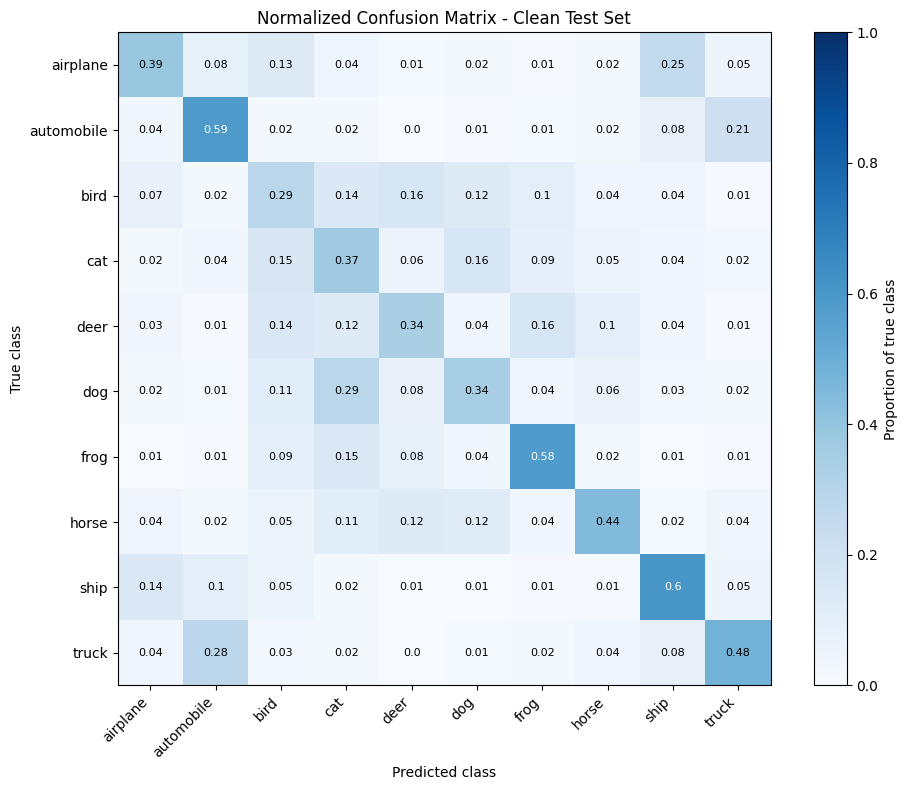


MOST CONFUSED CLASS PAIRS
-----------------------------------------------------------------
automobile <-> truck | Total: 492 | automobile predicted as truck: 211 | truck predicted as automobile: 281
cat <-> dog | Total: 447 | cat predicted as dog: 159 | dog predicted as cat: 288
airplane <-> ship | Total: 395 | airplane predicted as ship: 254 | ship predicted as airplane: 141
bird <-> deer | Total: 306 | bird predicted as deer: 162 | deer predicted as bird: 144
bird <-> cat | Total: 290 | bird predicted as cat: 140 | cat predicted as bird: 150

Number of misclassified images: 5576


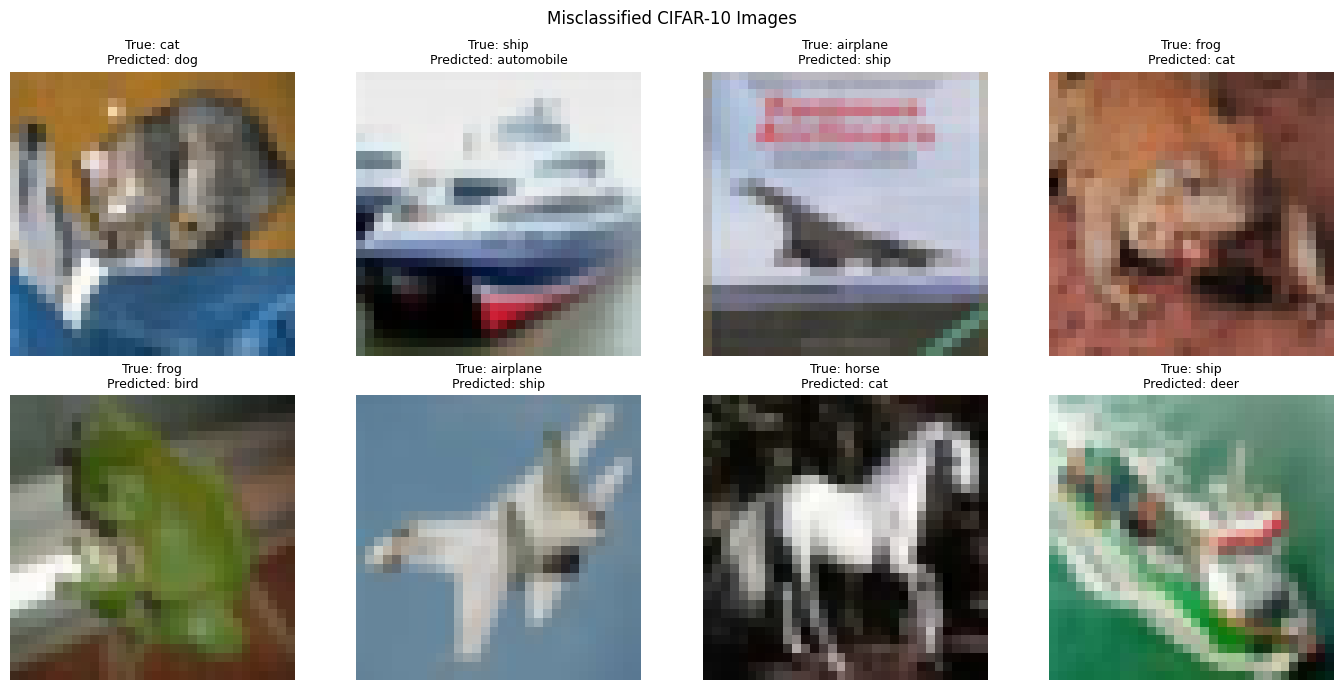


MISCLASSIFICATION DETAILS
--------------------------------------------------
1 | True: cat | Predicted: dog
2 | True: ship | Predicted: automobile
3 | True: airplane | Predicted: ship
4 | True: frog | Predicted: cat
5 | True: frog | Predicted: bird
6 | True: airplane | Predicted: ship
7 | True: horse | Predicted: cat
8 | True: ship | Predicted: deer

Applying hidden corruption to the clean test set...
Clean-test accuracy: 44.24 %
Hidden-corruption accuracy: 36.32 %
Accuracy drop: 7.92 percentage points
The model performed worse under this corruption.


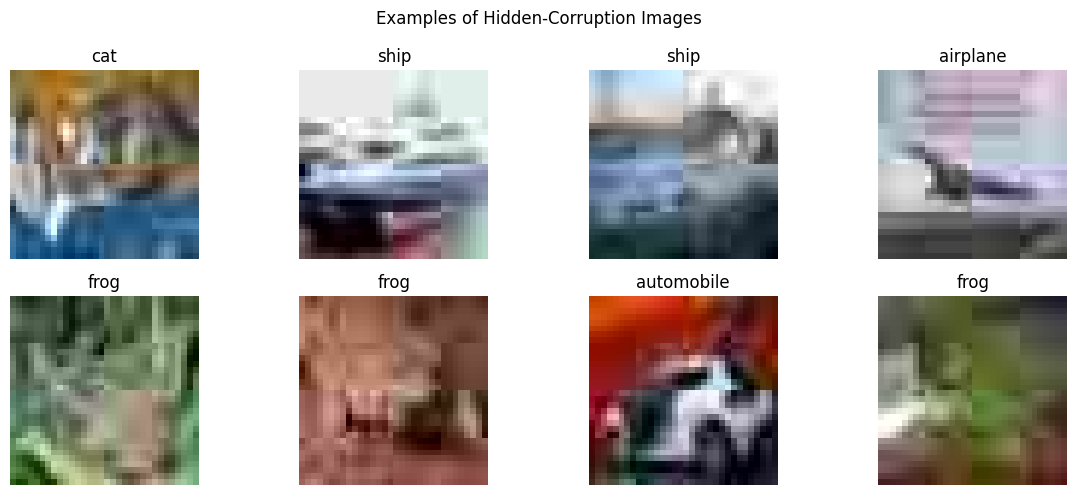

In [7]:

import io
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset


# CIFAR-10 class names
classNames = ["airplane", "automobile", "bird", "cat", "deer","dog", "frog", "horse", "ship", "truck"]

toPIL = transforms.ToPILImage()
toTensor = transforms.ToTensor()

# Load final model
finalSeed = 42

model = BaselineCNN().to(device)
model.load_state_dict(savedModels[finalConfig][finalSeed])
model.eval()
print("Final configuration:", finalConfig)
print("Seed:", finalSeed)


# PART E - TASK 1
# Get predictions
def getPredictions(model, loader):
    model.eval()

    allPredictions = []
    allLabels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            for i in range(len(predictions)):
                allPredictions.append(predictions[i].item())
                allLabels.append(labels[i].item())
    return np.array(allLabels), np.array(allPredictions)

trueLabels, predictedLabels = getPredictions(model, cleanLoader)

# Create confusion matrix
confusionMatrix = np.zeros((10, 10), dtype=int)

for i in range(len(trueLabels)):
    trueLabel = trueLabels[i]
    predictedLabel = predictedLabels[i]
    confusionMatrix[trueLabel, predictedLabel] += 1

# Calculate accuracy for each class
print("\nPER-CLASS ACCURACY")
print("-" * 40)

classAccuracies = []

for classIndex in range(10):
    correct = confusionMatrix[classIndex, classIndex]
    total = confusionMatrix[classIndex].sum()

    if total > 0:
        accuracy = 100 * correct / total
    else:
        accuracy = 0

    classAccuracies.append(accuracy)
    print(classNames[classIndex] + ": " + str(round(accuracy, 2)) + "%")

overallAccuracy = 100 * np.trace(confusionMatrix) / confusionMatrix.sum()
print("\nOverall clean-test accuracy:", round(overallAccuracy, 2), "%")

# Normalize confusion matrix
normalizedMatrix = np.zeros((10, 10), dtype=float)

for i in range(10):
    total = confusionMatrix[i].sum()

    if total > 0:
        for j in range(10):
            normalizedMatrix[i, j] = confusionMatrix[i, j] / total


# Plot normalized confusion matrix
plt.figure(figsize=(10, 8))
plt.imshow(normalizedMatrix, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Proportion of true class")

plt.xticks(range(10), classNames, rotation=45, ha="right")
plt.yticks(range(10), classNames)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Normalized Confusion Matrix - Clean Test Set")

for i in range(10):
    for j in range(10):
        value = normalizedMatrix[i, j]

        if value > 0.5:
            textColor = "white"
        else:
            textColor = "black"
        plt.text(j, i, str(round(value, 2)),ha="center", va="center",color=textColor, fontsize=8)
plt.tight_layout()
plt.show()

# Find most confused class pairs
pairConfusions = []

for i in range(10):
    for j in range(i + 1, 10):
        confusionCount = confusionMatrix[i, j] + confusionMatrix[j, i]

        pairConfusions.append((confusionCount, classNames[i], classNames[j],confusionMatrix[i, j], confusionMatrix[j, i]))
pairConfusions.sort(reverse=True)

print("\nMOST CONFUSED CLASS PAIRS")
print("-" * 65)

for i in range(5):
    count, classA, classB, aToB, bToA = pairConfusions[i]
    print(classA + " <-> " + classB+ " | Total: " + str(count)+ " | " + classA + " predicted as " + classB + ": " + str(aToB)+ " | " + classB + " predicted as " + classA + ": " + str(bToA))


# PART E - TASK 3
wrongIndices = []

for i in range(len(trueLabels)):
    if trueLabels[i] != predictedLabels[i]:
        wrongIndices.append(i)

print("\nNumber of misclassified images:", len(wrongIndices))
numberToShow = 8
if len(wrongIndices) < 8:
    numberToShow = len(wrongIndices)


if numberToShow > 0:
    plt.figure(figsize=(14, 7))
    for position in range(numberToShow):
        imageIndex = wrongIndices[position]

        image = x_clean[imageIndex].cpu().numpy()
        image = np.transpose(image, (1, 2, 0))
        image = np.clip(image, 0, 1)

        trueClass = classNames[trueLabels[imageIndex]]
        predictedClass = classNames[predictedLabels[imageIndex]]

        plt.subplot(2, 4, position + 1)
        plt.imshow(image)
        plt.title("True: " + trueClass+ "\nPredicted: " + predictedClass,fontsize=9)
        plt.axis("off")

    plt.suptitle("Misclassified CIFAR-10 Images")
    plt.tight_layout()
    plt.show()


# Print misclassification details
print("\nMISCLASSIFICATION DETAILS")
print("-" * 50)

for position in range(numberToShow):
    imageIndex = wrongIndices[position]

    print(str(position + 1)+ " | True: " + classNames[trueLabels[imageIndex]]+ " | Predicted: " + classNames[predictedLabels[imageIndex]])

# Hidden corruption test

def applyHiddenCorruption(imageTensor):
    image = toPIL(imageTensor.cpu())
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=15)
    buffer.seek(0)
    corruptedImage = Image.open(buffer).convert("RGB")
    return toTensor(corruptedImage)


print("\nApplying hidden corruption to the clean test set...")

corruptedImages = []

for image in x_clean:
    corruptedImage = applyHiddenCorruption(image)
    corruptedImages.append(corruptedImage)

x_hidden = torch.stack(corruptedImages)
hiddenDataset = TensorDataset(x_hidden, y_clean)

hiddenLoader = DataLoader(hiddenDataset,batch_size=100,shuffle=False)
hiddenTrue, hiddenPredicted = getPredictions(model, hiddenLoader)

# Calculate hidden-corruption accuracy
correct = 0
for i in range(len(hiddenTrue)):
    if hiddenTrue[i] == hiddenPredicted[i]:
        correct += 1

hiddenAccuracy = 100 * correct / len(hiddenTrue)

print("Clean-test accuracy:", round(overallAccuracy, 2), "%")
print("Hidden-corruption accuracy:", round(hiddenAccuracy, 2), "%")
accuracyDrop = overallAccuracy - hiddenAccuracy
print("Accuracy drop:", round(accuracyDrop, 2), "percentage points")

if accuracyDrop > 0:
    print("The model performed worse under this corruption.")
elif accuracyDrop < 0:
    print("The model performed better on this corrupted test set.")
else:
    print("Accuracy remained unchanged.")

# Display hidden-corruption examples
plt.figure(figsize=(12, 5))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    image = x_hidden[i].cpu().numpy()
    image = np.transpose(image, (1, 2, 0))
    image = np.clip(image, 0, 1)

    plt.imshow(image)
    plt.title(classNames[y_clean[i].item()])
    plt.axis("off")

plt.suptitle("Examples of Hidden-Corruption Images")
plt.tight_layout()
plt.show()
